In [ ]:
!git clone -q https://github.com/sopipi180/ComputerVisionandSpeechRecognition.git
%cd ComputerVisionandSpeechRecognition
!python m1_data/Session1/session1.py

/content/ComputerVisionandSpeechRecognition
Downloading: 100.0%  (345 MB / 345 MB)
Download complete.
Extracting...
Extraction complete.
Number of images: 10480
(10480, 17) (5240, 12)
5240 unique lesions
age_approx             0.003817
sex                    0.000000
anatom_site_general    0.373282
dtype: float64
Every lesion has exactly 2 images: True
diagnosis_1
Malignant        7268
Benign           2966
Indeterminate     246
Name: count, dtype: int64
Figure(600x400)
BCC        2522
NV          746
BKL         544
SCCKA       473
MEL         450
AKIEC       303
DF           52
INF          50
VASC         47
BEN_OTH      44
MAL_OTH       9
dtype: int64
Figure(900x400)
                min   max       mean  count
diagnosis_1                                
Benign          5.0  85.0  51.575530   2926
Indeterminate  35.0  85.0  67.764228    246
Malignant      20.0  85.0  65.075674   7268
Figure(600x400)
Figure(640x480)
sex            female  male
diagnosis_1                
Benign      

##0. Setup

In [ ]:
import sys, copy, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

# Local: walk up to the repo. Colab: the repo was cloned by the setup cell.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "common" / "config.py").is_file())
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "m3_deep" / "Session6"))

from common import config
import data as D

np.set_printoptions(precision=3, suppress=True)
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
print("torch", torch.__version__, "| repo:", ROOT.name)

torch 2.11.0+cpu | repo: ComputerVisionandSpeechRecognition


##1. One neuron, by hand then in NumPy

A neuron does two things: a weighted sum z = w·x + b, then an activation that squashes
it. With a sigmoid, one neuron **is** logistic regression.

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def neuron(x, w, b):
    z = x @ w + b              # 1. weighted sum: a score
    return z, sigmoid(z)       # 2. activation: squashed into (0, 1)

x = np.array([0.6, 0.2])       # edge density, asymmetry (normalised)
w = np.array([1.5, -0.5])
b = -0.4
z, y_hat = neuron(x, w, b)
print(f"z = {z:.3f}, sigmoid(z) = {y_hat:.3f}")

z = 0.400, sigmoid(z) = 0.599


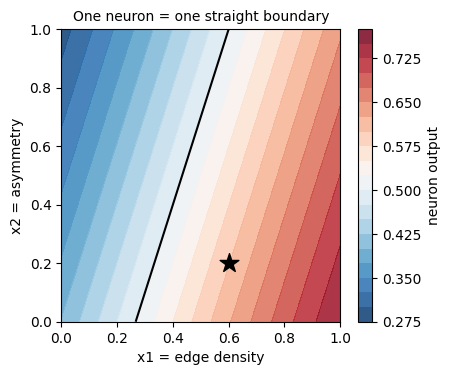

In [ ]:
# colour every possible input by the neuron's output: the boundary is a straight line
g1, g2 = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
_, p = neuron(np.stack([g1, g2], axis=-1), w, b)

plt.figure(figsize=(4.5, 3.8))
plt.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.85)
plt.colorbar(label="neuron output")
plt.contour(g1, g2, p, levels=[0.5], colors="k")      # y_hat = 0.5 <=> z = 0
plt.scatter(*x, c="k", marker="*", s=200)
plt.xlabel("x1 = edge density"); plt.ylabel("x2 = asymmetry")
plt.title("One neuron = one straight boundary", fontsize=10); plt.show()

## 2. XOR — what one straight line cannot do

No single line separates XOR. Two layers with a ReLU in between can.

In [ ]:
def relu(z):
    return np.maximum(0, z)

X_xor = np.array([[0., 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

W1 = np.array([[1., 1], [1, 1]])      # column j = weights of hidden neuron j
b1 = np.array([0., -1])               # h1 = how many inputs are on; h2 = are both on
W2 = np.array([1., -2])

H = relu(X_xor @ W1 + b1)
out = H @ W2
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1],
              "h1": H[:, 0], "h2": H[:, 1], "output": out, "XOR": y_xor})

,x1,x2,h1,h2,output,XOR
0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,1.0,1.0,0.0,1.0,1
2,1.0,0.0,1.0,0.0,1.0,1
3,1.0,1.0,2.0,1.0,0.0,0


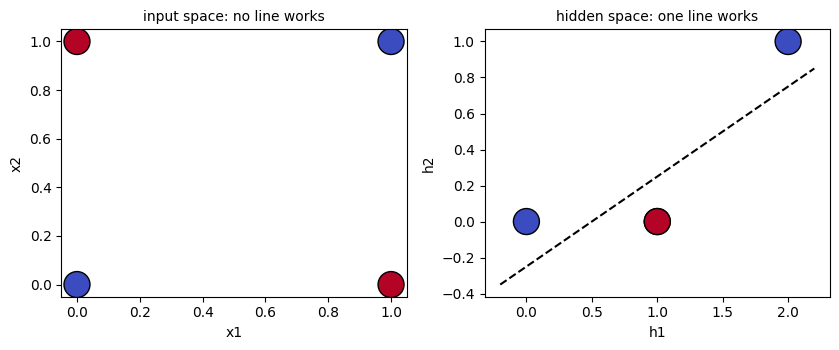

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=350, edgecolors="k")
axes[0].set_title("input space: no line works", fontsize=10)
axes[1].scatter(H[:, 0], H[:, 1], c=y_xor, cmap="coolwarm", s=350, edgecolors="k")
line = np.linspace(-0.2, 2.2, 10)
axes[1].plot(line, (line - 0.5) / 2, "k--")
axes[1].set_title("hidden space: one line works", fontsize=10)
for ax, (a, b_) in zip(axes, [("x1", "x2"), ("h1", "h2")]):
    ax.set_xlabel(a); ax.set_ylabel(b_)
plt.tight_layout(); plt.show()

In [ ]:
# the same network WITHOUT ReLU collapses into a single linear layer
linear_out = (X_xor @ W1 + b1) @ W2
collapsed = X_xor @ (W1 @ W2) + (b1 @ W2)
print("no ReLU:", linear_out, " one equivalent layer:", collapsed)
print("-> not XOR. Without a nonlinearity, 100 layers equal 1 layer.")

no ReLU: [2. 1. 1. 0.]  one equivalent layer: [2. 1. 1. 0.]
-> not XOR. Without a nonlinearity, 100 layers equal 1 layer.


## 3. Forward pass, softmax and cross-entropy

Three output neurons give three raw scores (**logits**). Softmax turns them into
probabilities; cross-entropy measures how wrong the probability of the *true* class is.

In [ ]:
def forward(x, W1, b1, W2, b2):
    z_h = x @ W1 + b1
    h = relu(z_h)
    return sigmoid(h @ W2 + b2), h, z_h

W1f = np.array([[0.5, -0.3], [0.3, 0.4]]); b1f = np.array([0.1, -0.3])
W2f = np.array([0.4, -0.2]);               b2f = 0.1
y_hat_f, h_f, z_h_f = forward(np.array([0.6, 0.2]), W1f, b1f, W2f, b2f)
print("z_h =", z_h_f, " h =", h_f, " y_hat =", round(y_hat_f, 3))   # slides: 0.570
print("the second hidden neuron is off (0): it gets no gradient from this lesion")

z_h = [ 0.46 -0.4 ]  h = [0.46 0.  ]  y_hat = 0.571
the second hidden neuron is off (0): it gets no gradient from this lesion


In [ ]:
def softmax(z):
    e = np.exp(z - z.max())        # subtract the max: same answer, no overflow
    return e / e.sum()

logits = np.array([1.0, 2.0, 0.5])            # Benign, Malignant, Indeterminate
print("exp:    ", np.exp(logits))
print("softmax:", softmax(logits), " sum =", softmax(logits).sum())

exp:     [2.718 7.389 1.649]
softmax: [0.231 0.629 0.14 ]  sum = 1.0


In [ ]:
def cross_entropy(onehot, probs, eps=1e-9):
    return -np.sum(onehot * np.log(np.clip(probs, eps, 1 - eps)))

truth = np.array([0, 1, 0])                   # Malignant
for probs in ([0.10, 0.70, 0.20], [0.005, 0.99, 0.005], [0.80, 0.10, 0.10]):
    print(probs, "->", round(cross_entropy(truth, np.array(probs)), 3))
print("confident and wrong costs ~230x a confident hit")

[0.1, 0.7, 0.2] -> 0.357
[0.005, 0.99, 0.005] -> 0.01
[0.8, 0.1, 0.1] -> 2.303
confident and wrong costs ~230x a confident hit


## 4. Gradient descent, and why the learning rate is the touchiest knob

In [ ]:
def descend(lr, w=0.0, steps=15):
    path = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)        # slope of L(w) = (w - 3)^2
        w = w - lr * grad         # one step downhill
        path.append(w)
    return np.array(path)

print("lr=0.1 first steps:", descend(0.1)[:4], "-> final", round(descend(0.1)[-1], 3))

lr=0.1 first steps: [0.    0.6   1.08  1.464] -> final 2.894


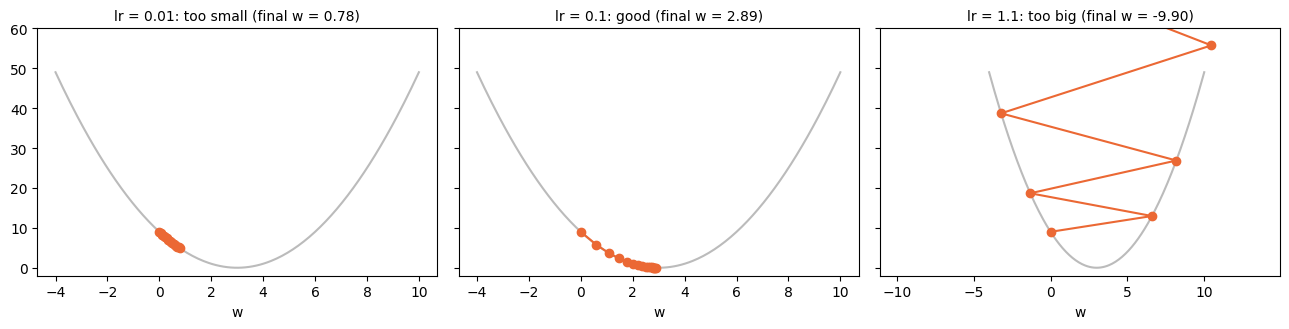

In [ ]:
ws = np.linspace(-4, 10, 200)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, lr, label in zip(axes, [0.01, 0.1, 1.1], ["too small", "good", "too big"]):
    path = descend(lr, steps=8 if lr > 1 else 15)
    ax.plot(ws, (ws - 3) ** 2, color="#BBBBBB")
    ax.plot(path, (path - 3) ** 2, "o-", color="#eb6834")
    ax.set_title(f"lr = {lr}: {label} (final w = {path[-1]:.2f})", fontsize=10)
    ax.set_ylim(-2, 60); ax.set_xlabel("w")
plt.tight_layout(); plt.show()

## 5. Backpropagation by hand, then checked against PyTorch

Backprop is the chain rule run backwards. For sigmoid + cross-entropy the whole chain
collapses to dz = prediction − truth.

In [ ]:
y = 1.0                                       # truth: malignant
z, y_hat = neuron(x, w, b)
loss = -np.log(y_hat)
dz = y_hat - y                                # the shortcut
grad_w, grad_b = dz * x, dz * 1.0
print(f"forward : z={z:.3f}  y_hat={y_hat:.3f}  loss={loss:.3f}")
print(f"backward: dz={dz:.3f}  grad_w={grad_w}  grad_b={grad_b:.3f}")

w_new, b_new = w - 1.0 * grad_w, b - 1.0 * grad_b    # one step, lr = 1
_, y_hat2 = neuron(x, w_new, b_new)
print(f"after one step: y_hat {y_hat:.3f} -> {y_hat2:.3f}, "
      f"loss {loss:.3f} -> {-np.log(y_hat2):.3f}")

forward : z=0.400  y_hat=0.599  loss=0.513
backward: dz=-0.401  grad_w=[-0.241 -0.08 ]  grad_b=-0.401
after one step: y_hat 0.599 -> 0.723, loss 0.513 -> 0.324


In [ ]:
# PyTorch's autograd should reproduce the gradients above exactly
xt = torch.tensor([0.6, 0.2])
wt = torch.tensor([1.5, -0.5], requires_grad=True)
bt = torch.tensor(-0.4, requires_grad=True)

loss_t = -torch.log(torch.sigmoid(xt @ wt + bt))
loss_t.backward()
print("autograd grad_w:", wt.grad.numpy(), " grad_b:", bt.grad.item())
print("matches my hand calculation:",
      np.allclose(wt.grad.numpy(), grad_w, atol=1e-6))

autograd grad_w: [-0.241 -0.08 ]  grad_b: -0.40131232142448425
matches my hand calculation: True


## 6. More neurons, more bends

Each hidden ReLU neuron adds one bend to the boundary. Universal approximation says a wide
enough hidden layer can fit any continuous function.

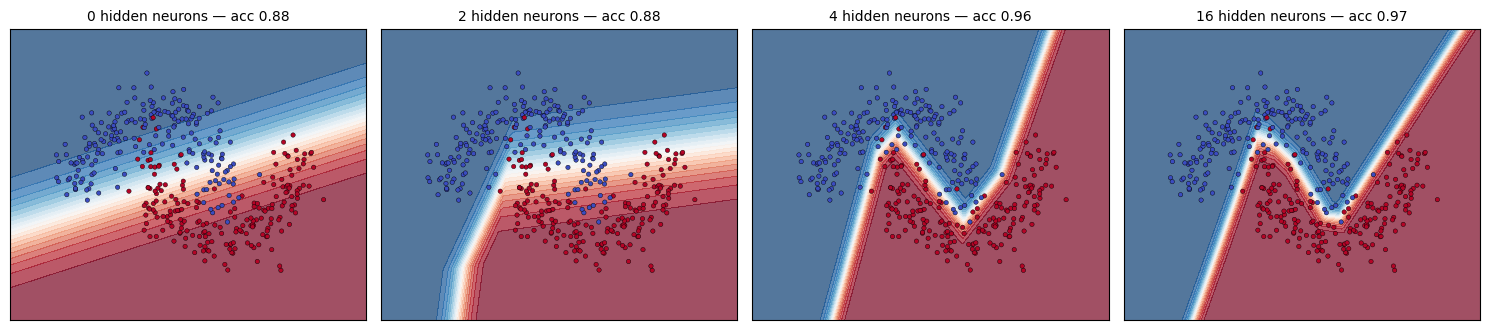

In [ ]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=SEED)
Xm_t, ym_t = torch.tensor(Xm, dtype=torch.float32), torch.tensor(ym)

def make_net(hidden):
    torch.manual_seed(SEED)
    if hidden == 0:
        return nn.Linear(2, 2)                      # no hidden layer = logistic regression
    return nn.Sequential(nn.Linear(2, hidden), nn.ReLU(), nn.Linear(hidden, 2))

def quick_train(net, X, y, epochs=800, lr=0.01):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(net(X), y)
        loss.backward()
        optimizer.step()
    return loss.item()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
g1m, g2m = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.5, 2, 150))
grid = torch.tensor(np.c_[g1m.ravel(), g2m.ravel()], dtype=torch.float32)
for ax, hidden in zip(axes, [0, 2, 4, 16]):
    net = make_net(hidden)
    quick_train(net, Xm_t, ym_t)
    with torch.no_grad():
        prob = torch.softmax(net(grid), 1)[:, 1].reshape(g1m.shape)
        acc = (net(Xm_t).argmax(1) == ym_t).float().mean().item()
    ax.contourf(g1m, g2m, prob, levels=20, cmap="RdBu_r", alpha=0.7)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(f"{hidden} hidden neurons — acc {acc:.2f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 7. Back to MILK10k — Session 5's 33 features

The split is Session 3's, made per lesion so the two photos of a lesion never end up on
opposite sides. Dermoscopic photos only, which is what Session 5 chose, so the numbers stay
comparable.

In [ ]:
splits = D.load_splits(view="dermoscopic")
ids_all = pd.concat([df["isic_id"] for df in splits.values()])
feats = D.load_features(ids=ids_all)        # computes them if the Session 5 cache is missing

X = {k: D.feature_matrix(df, feats) for k, df in splits.items()}
y = {k: D.encode(df[D.TARGET]) for k, df in splits.items()}

# standardise with TRAIN statistics only (Session 3's no-leakage rule)
mu, sd = X["train"].mean(0), X["train"].std(0) + 1e-8
X = {k: ((v - mu) / sd).astype("float32") for k, v in X.items()}

for k in ("train", "val", "test"):
    print(f"{k:<6} {X[k].shape}  {dict(zip(D.CLASSES, np.bincount(y[k], minlength=3)))}")

train  (3667, 33)  {'Benign': np.int64(1051), 'Malignant': np.int64(2528), 'Indeterminate': np.int64(88)}
val    (786, 33)  {'Benign': np.int64(226), 'Malignant': np.int64(542), 'Indeterminate': np.int64(18)}
test   (787, 33)  {'Benign': np.int64(206), 'Malignant': np.int64(564), 'Indeterminate': np.int64(17)}


In [ ]:
# a rare class must not be ignorable: weight the loss by n / (3 * n_c)
weights = D.class_weights(y["train"])
print(dict(zip(D.CLASSES, weights.round(2))))
print(f"missing an Indeterminate now costs {weights[D.CLASSES.index('Indeterminate')] / weights[D.CLASSES.index('Malignant')]:.0f}x missing a Malignant")
class_weights = torch.tensor(weights, dtype=torch.float32)

{'Benign': np.float64(1.16), 'Malignant': np.float64(0.48), 'Indeterminate': np.float64(13.89)}
missing an Indeterminate now costs 29x missing a Malignant


## 8. An MLP on MILK10k — mini-batches, epochs, curves

`Linear(33→64) → ReLU → Linear(64→3)`. Three logits and **no softmax**: it lives inside
`nn.CrossEntropyLoss`.

In [ ]:
def make_mlp(d_in=33, hidden=(64,), dropout=0.0, seed=SEED):
    torch.manual_seed(seed)                      # identical starting weights every run
    layers = []
    for h in hidden:
        layers += [nn.Linear(d_in, h), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        d_in = h
    layers.append(nn.Linear(d_in, 3))
    return nn.Sequential(*layers)

n_params = lambda m: sum(p.numel() for p in m.parameters())
model = make_mlp()
print(model)
print("parameters:", n_params(model), " (slides: 33*64+64 + 64*3+3 = 2,371)")

Sequential(
  (0): Linear(in_features=33, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=3, bias=True)
)
parameters: 2371  (slides: 33*64+64 + 64*3+3 = 2,371)


In [ ]:
def fit(model, Xtr, ytr, Xva, yva, epochs=50, lr=1e-3, weight_decay=0.0, batch_size=64):
    """Train, and record train loss / val loss / val macro-F1 every epoch."""
    loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)),
                        batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    Xva_t, yva_t = torch.from_numpy(Xva), torch.from_numpy(yva)
    history = []
    for epoch in range(epochs):
        model.train(); total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()           # 1. forget old gradients
            loss = loss_fn(model(xb), yb)   # 2. forward + loss
            loss.backward()                 # 3. backprop
            optimizer.step()                # 4. w <- w - lr * grad
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            logits = model(Xva_t)
            history.append({"epoch": epoch,
                            "train_loss": total / len(ytr),
                            "val_loss": loss_fn(logits, yva_t).item(),
                            "val_f1": f1_score(yva, logits.argmax(1).numpy(),
                                               average="macro", zero_division=0)})
    return pd.DataFrame(history).set_index("epoch")

def predict(model, Xarr):
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(Xarr)).argmax(1).numpy()

loader_demo = DataLoader(TensorDataset(torch.from_numpy(X["train"]),
                                       torch.from_numpy(y["train"])),
                         batch_size=64, shuffle=True)
print(len(loader_demo), "mini-batches of 64 per epoch")

58 mini-batches of 64 per epoch


In [ ]:
hist = fit(model, X["train"], y["train"], X["val"], y["val"], epochs=50)
mlp_val_f1 = f1_score(y["val"], predict(model, X["val"]), average="macro", zero_division=0)
print(f"MLP validation macro-F1 = {mlp_val_f1:.3f}")
hist.tail(3).round(3)

MLP validation macro-F1 = 0.463


,train_loss,val_loss,val_f1
epoch,,,
47,0.642,0.926,0.471
48,0.643,0.928,0.472
49,0.647,0.928,0.463


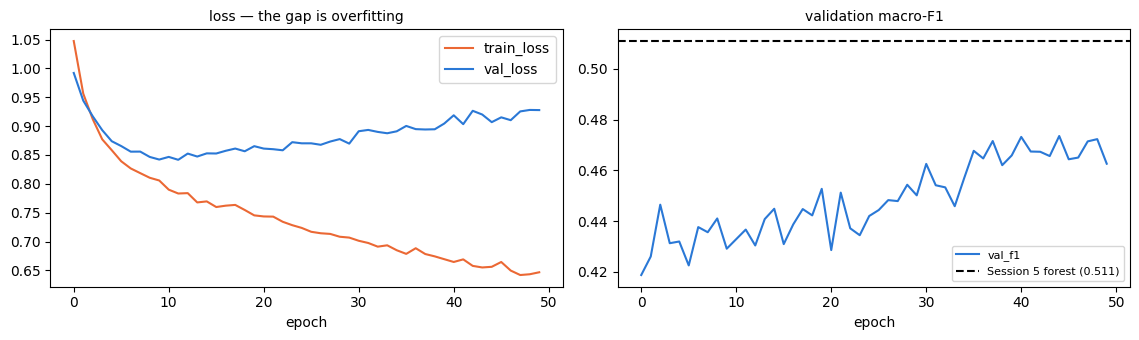

In [ ]:
FOREST_VAL, FOREST_TEST = 0.511, 0.525

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
hist[["train_loss", "val_loss"]].plot(ax=axes[0], color=["#eb6834", "#2a78d6"])
axes[0].set_title("loss — the gap is overfitting", fontsize=10)
hist["val_f1"].plot(ax=axes[1], color="#2a78d6")
axes[1].axhline(FOREST_VAL, color="k", ls="--", label=f"Session 5 forest ({FOREST_VAL})")
axes[1].set_title("validation macro-F1", fontsize=10); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
cm = pd.DataFrame(confusion_matrix(y["val"], predict(model, X["val"]), labels=[0, 1, 2]),
                  index=[f"true {c}" for c in D.CLASSES],
                  columns=[f"pred {c}" for c in D.CLASSES])
cm

,pred Benign,pred Malignant,pred Indeterminate
true Benign,136,68,22
true Malignant,112,329,101
true Indeterminate,0,9,9


## 9. Overfitting on purpose, and three cures

A much bigger network on the same 3,667 lesions: training loss keeps falling while
validation loss climbs. Dropout, weight decay and early stopping are the answer.

parameters: 75267


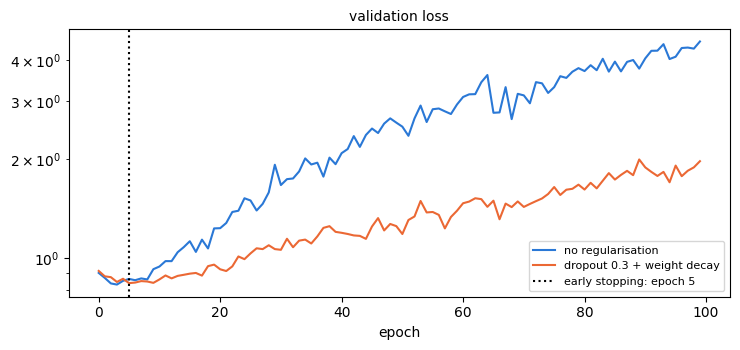

last epoch, no regularisation: {'train_loss': 0.143, 'val_loss': 4.567, 'val_f1': 0.498}
last epoch, regularised      : {'train_loss': 0.421, 'val_loss': 1.975, 'val_f1': 0.522}


In [ ]:
big = make_mlp(hidden=(256, 256))
print("parameters:", n_params(big))
hist_big = fit(big, X["train"], y["train"], X["val"], y["val"], epochs=100)

reg = make_mlp(hidden=(256, 256), dropout=0.3)
hist_reg = fit(reg, X["train"], y["train"], X["val"], y["val"],
               epochs=100, weight_decay=1e-4)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
hist_big["val_loss"].plot(ax=ax, label="no regularisation", color="#2a78d6", logy=True)
hist_reg["val_loss"].plot(ax=ax, label="dropout 0.3 + weight decay", color="#eb6834")
best_epoch = hist_reg["val_loss"].idxmin()
ax.axvline(best_epoch, color="k", ls=":", label=f"early stopping: epoch {best_epoch}")
ax.set_title("validation loss", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("last epoch, no regularisation:", hist_big.iloc[-1].round(3).to_dict())
print("last epoch, regularised      :", hist_reg.iloc[-1].round(3).to_dict())

## 10. The test set once and the scoreboard

The configuration is already decided, so the test split gets used a single time.

In [ ]:
test_pred = predict(model, X["test"])
mlp_test_f1 = f1_score(y["test"], test_pred, average="macro", zero_division=0)
mlp_test_acc = accuracy_score(y["test"], test_pred)
print(f"TEST accuracy = {mlp_test_acc:.3f}   TEST macro-F1 = {mlp_test_f1:.3f}")

TEST accuracy = 0.621   TEST macro-F1 = 0.483


In [ ]:
scoreboard = pd.DataFrame([                 # Session 5 rows from m2_baseline/Session5/results.txt
    {"model": "majority (always Malignant)",    "features": "none",    "val": 0.272, "test": 0.278},
    {"model": "logistic regression",            "features": "33",      "val": 0.435, "test": np.nan},
    {"model": "kNN (k=5)",                      "features": "33",      "val": 0.468, "test": np.nan},
    {"model": "random forest",                  "features": "33",      "val": 0.496, "test": np.nan},
    {"model": "random forest (Session 5 best)", "features": "24 hist", "val": FOREST_VAL, "test": FOREST_TEST},
])
scoreboard

,model,features,val,test
0,majority (always Malignant),none,0.272,0.278
1,logistic regression,33,0.435,NaN
2,kNN (k=5),33,0.468,NaN
3,random forest,33,0.496,NaN
4,random forest (Session 5 best),24 hist,0.511,0.525


## 11. Mini challenge — tune it

One change at a time, everything else fixed. Validation only; the test set stays closed.

In [ ]:
experiments = {
    "baseline  hidden=(64,)  lr=1e-3": dict(hidden=(64,),    lr=1e-3),
    "lr=0.1   (too big)":              dict(hidden=(64,),    lr=0.1),
    "lr=1e-5  (too small)":            dict(hidden=(64,),    lr=1e-5),
    "hidden=(4,)    (narrow)":         dict(hidden=(4,),     lr=1e-3),
    "hidden=(256,)  (wide)":           dict(hidden=(256,),   lr=1e-3),
    "hidden=(64,64) (deeper)":         dict(hidden=(64, 64), lr=1e-3),
}

rows = []
for name, cfg in experiments.items():
    net = make_mlp(hidden=cfg["hidden"])          # same seed -> same starting weights
    h = fit(net, X["train"], y["train"], X["val"], y["val"], epochs=50, lr=cfg["lr"])
    rows.append({"experiment": name, "params": n_params(net),
                 "final train loss": h["train_loss"].iloc[-1],
                 "final val loss": h["val_loss"].iloc[-1],
                 "final val F1": h["val_f1"].iloc[-1],
                 "best val F1": h["val_f1"].max()})
challenge = pd.DataFrame(rows).set_index("experiment").round(3)
challenge

,params,final train loss,final val loss,final val F1,best val F1
experiment,,,,,
"baseline hidden=(64,) lr=1e-3",2371,0.647,0.928,0.463,0.474
lr=0.1 (too big),2371,0.983,0.919,0.323,0.442
lr=1e-5 (too small),2371,1.031,1.037,0.410,0.410
"hidden=(4,) (narrow)",151,0.802,0.901,0.431,0.457
"hidden=(256,) (wide)",9475,0.542,1.099,0.486,0.502
"hidden=(64,64) (deeper)",6531,0.512,1.874,0.498,0.498


In [ ]:
ax = challenge["final val F1"].plot.barh(color="#eb6834", figsize=(7.5, 3.6))
ax.axvline(FOREST_VAL, color="k", ls="--", label=f"Session 5 forest ({FOREST_VAL})")
ax.set_xlabel("validation macro-F1"); ax.legend(fontsize=8); ax.invert_yaxis()
plt.tight_layout(); plt.show()

**What the table shows.** lr=0.1 takes steps so big they overshoot, so the loss jumps
around instead of settling. lr=1e-5 barely moves the weights in 50 epochs, so the train
loss is still near where it started. `hidden=(4,)` underfits--> four neurons cannot bend a
boundary in 33 dimensions. `hidden=(256,)` and `(64,64)` fit the training set much better
than the validation set, which is the overfitting gap from section 9 appearing.

The pattern across all of them: no small MLP clearly beats the forest on these 33 numbers.
The bottleneck is the features, not the classifier

---
# Homework --> before Session 7

1. Add the MLP's validation and test macro-F1 to the scoreboard, next to Session 5's forest.
2. Read the docs of `nn.Conv2d`: which arguments are Session 4's kernel size, stride and padding?
3. Train the MLP on raw pixels (32×32×3 = 3,072 numbers). Better or worse than the 33 features? Why?

## Homework 1 - the scoreboard

In [ ]:
scoreboard = pd.concat([scoreboard, pd.DataFrame([
    {"model": "MLP 33-64-3 (Session 6)", "features": "33",
     "val": round(mlp_val_f1, 3), "test": round(mlp_test_f1, 3)}])], ignore_index=True)
display(scoreboard)

for label, mine, forest in [("validation", mlp_val_f1, FOREST_VAL),
                            ("test", mlp_test_f1, FOREST_TEST)]:
    gap = mine - forest
    print(f"{label:<11} MLP {mine:.3f} {'beats' if gap > 0 else 'falls short of'} "
          f"the Session 5 forest ({forest:.3f}) by {abs(gap):.3f}")

,model,features,val,test
0,majority (always Malignant),none,0.272,0.278
1,logistic regression,33,0.435,NaN
2,kNN (k=5),33,0.468,NaN
3,random forest,33,0.496,NaN
4,random forest (Session 5 best),24 hist,0.511,0.525
5,MLP 33-64-3 (Session 6),33,0.463,0.483


validation  MLP 0.463 falls short of the Session 5 forest (0.511) by 0.048
test        MLP 0.483 falls short of the Session 5 forest (0.525) by 0.042


**Answer 1.** The MLP's scores are the last row of the table, and the lines under it
compare them with Session 5's forest.

They come out close, which makes sense. A forest is very good at small tables of numbers.
My MLP has only 2,371 weights and 3,667 lesions to learn from. Not enough for a network
to show any advantage.

## Homework 2 — `nn.Conv2d` and Session 4

In [ ]:
# Session 4's Sobel kernel, loaded into nn.Conv2d by hand
from PIL import Image
from scipy import ndimage

sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])
conv = nn.Conv2d(1, 1, kernel_size=3, stride=1, padding=1, bias=False)
with torch.no_grad():
    conv.weight.copy_(sobel_x.view(1, 1, 3, 3))

gray = np.asarray(Image.open(config.image_path(splits["val"]["isic_id"].iloc[0]))
                  .convert("L").resize((160, 120)), dtype=np.float32)
with torch.no_grad():
    torch_out = conv(torch.from_numpy(gray).view(1, 1, *gray.shape)).squeeze().numpy()
scipy_out = ndimage.correlate(gray, sobel_x.numpy(), mode="constant")
print("matches Session 4's scipy version:", np.allclose(torch_out, scipy_out, atol=1e-3))

rows = [{"kernel": k, "stride": s, "padding": p,
         "32x32 ->": nn.Conv2d(1, 1, k, s, p)(torch.zeros(1, 1, 32, 32)).shape[-1],
         "formula": (32 + 2 * p - k) // s + 1}
        for k, s, p in [(3, 1, 1), (3, 1, 0), (3, 2, 1), (5, 1, 2), (5, 2, 0), (7, 1, 3)]]
pd.DataFrame(rows)

matches Session 4's scipy version: True


,kernel,stride,padding,32x32 ->,formula
0,3,1,1,32,32
1,3,1,0,30,30
2,3,2,1,16,16
3,5,1,2,32,32
4,5,2,0,14,14
5,7,1,3,32,32


**Answer 2.** `kernel_size` is the window size (3 means 3×3, like my Sobel filter),
`stride` is how far the window jumps, and `padding` is the border added so it still fits
at the edges.

I checked instead of only reading: Session 4's Sobel kernel inside an `nn.Conv2d` gives
the same result as scipy, and the output sizes match the formula every time.

One additional thing, I had to compare with `ndimage.correlate`, not `convolve`, because PyTorch
does not flip the kernel. That only matters when you type the numbers in yourself, as I
did here.

## Homework 3 -the same MLP on raw pixels

Each photo shrunk to 32×32 and flattened: 3,072 numbers, nothing designed by me.

In [ ]:
Xp = {k: D.load_pixels(df["isic_id"]).astype("float32") for k, df in splits.items()}

# standardise with TRAIN statistics only, exactly as for the features
mu_p, sd_p = Xp["train"].mean(0), Xp["train"].std(0) + 1e-8
Xp = {k: ((v - mu_p) / sd_p).astype("float32") for k, v in Xp.items()}
print({k: v.shape for k, v in Xp.items()})

pix_model = make_mlp(d_in=Xp["train"].shape[1], hidden=(64,))
hist_pix = fit(pix_model, Xp["train"], y["train"], Xp["val"], y["val"], epochs=50)

pix_val_f1 = f1_score(y["val"], predict(pix_model, Xp["val"]), average="macro", zero_division=0)
pix_test_f1 = f1_score(y["test"], predict(pix_model, Xp["test"]), average="macro", zero_division=0)
print(f"\n33 features     : val {mlp_val_f1:.3f}, test {mlp_test_f1:.3f}, "
      f"{n_params(model):,} parameters")
print(f"3,072 raw pixels: val {pix_val_f1:.3f}, test {pix_test_f1:.3f}, "
      f"{n_params(pix_model):,} parameters")
gap = pix_test_f1 - mlp_test_f1
print(f"raw pixels are {abs(gap):.3f} {'better' if gap > 0 else 'worse'} on test, "
      f"with {n_params(pix_model) / n_params(model):.0f}x the parameters")

decoding 3667 images at 32x32 ...
  1000/3667
  2000/3667
  3000/3667
wrote /content/ComputerVisionandSpeechRecognition/Session6/pixels_32.npz
decoding 786 images at 32x32 ...
wrote /content/ComputerVisionandSpeechRecognition/Session6/pixels_32.npz
decoding 787 images at 32x32 ...
wrote /content/ComputerVisionandSpeechRecognition/Session6/pixels_32.npz
{'train': (3667, 3072), 'val': (786, 3072), 'test': (787, 3072)}

33 features     : val 0.463, test 0.483, 2,371 parameters
3,072 raw pixels: val 0.524, test 0.456, 196,867 parameters
raw pixels are 0.028 worse on test, with 83x the parameters


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
hist["val_f1"].plot(ax=axes[0], label="33 features", color="#2a78d6")
hist_pix["val_f1"].plot(ax=axes[0], label="3,072 raw pixels", color="#eb6834")
axes[0].axhline(FOREST_VAL, color="k", ls="--", lw=1)
axes[0].set_title("validation macro-F1", fontsize=10); axes[0].legend(fontsize=8)

hist_pix[["train_loss", "val_loss"]].plot(ax=axes[1], color=["#eb6834", "#2a78d6"])
axes[1].set_title("raw pixels: train loss falls, val loss does not", fontsize=10)
plt.tight_layout(); plt.show()

scoreboard = pd.concat([scoreboard, pd.DataFrame([
    {"model": "MLP 3072-64-3 (Session 6)", "features": "raw pixels 32x32x3",
     "val": round(pix_val_f1, 3), "test": round(pix_test_f1, 3)}])], ignore_index=True)
scoreboard

**Answer 3.** The cell above says which one won. Why raw pixels struggle:

**It does not know pixels are neighbours.** Pixel 1,500 is just input 1,500 to the MLP.
Move the lesion slightly and every input changes. A histogram gives the same number
wherever the lesion sits.

**Too many weights.** About 2,400 becomes about 197,000, from the same 3,667 lesions. It
memorises instead of learning — you can see it in the loss curves.

**The 33 features already know something.** Colour, texture and borders are what
dermatologists look at. Raw pixels have none of that built in.

**32×32 is tiny.** It throws away the fine texture Session 4's filters measured.

**A CNN fixes this.** One small kernel slides over the whole image, so a 3×3 kernel is 9
weights instead of one per pixel. That is the `nn.Conv2d` from question 2.